# 03 · Feature Selection for the Controlled Experiment

**Goal:** choose 4 jet features that actually separate quark from gluon jets, and check that raw amplitude encoding collapses on them too.

| Section | Question | Output |
| --- | --- | --- |
| 1 | Are the candidate features clean (no sentinel values, no NaN)? | Sanity table |
| 2 | How do quark and gluon jets differ in each feature? | Fig. 5 — distributions |
| 3 | How much does each feature separate the classes on its own? | Single-feature AUC table |
| 4 | Which features are redundant? | Correlation table |
| 5 | Do the chosen features have very different scales? | Scale table |
| 6 | Does raw amplitude encoding collapse on the chosen features? | Fig. 6 — dominant-state probability |

The 4 kinematic features (pT, η, ϕ, m) are included in the AUC table as a reference: they were expected to be close to 0.5. Outcome: η, ϕ ≈ 0.50 and m 0.56, but pT gives 0.66 because the quark fraction of this flat-pT-hat sample rises with pT (see notebook 13).

**How to run:** kernel `qt4hep` → **Run All**.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from jet_data import load_jets, select_quark_gluon, feature_matrix, event_level_split, BOOKKEEPING
from quantum_encodings import amplitude_probabilities
from figure_style import set_style, save, COLORS, SURFACE

set_style()
SEED = 42

KINEMATIC = ("jetPt", "jetEta", "jetPhi", "jetMass")
CANDIDATES = ("QG_mult", "QG_ptD", "QG_axis2", "jetGirth", "jetMult")
REFERENCE = ("jetQGl",)   # CMS quark-gluon likelihood, used only as a benchmark

LABELS = {
    "QG_mult": "constituent multiplicity (QG cuts)",
    "QG_ptD": r"$p_T D$ (momentum dispersion)",
    "QG_axis2": "minor axis (axis2)",
    "jetGirth": "girth",
    "jetMult": "constituent multiplicity (all)",
}

In [2]:
raw = load_jets(features=KINEMATIC + CANDIDATES + REFERENCE, extra=BOOKKEEPING)
jets = select_quark_gluon(raw, require_loose_id=True)
y = jets["label"]                                  # 1 = quark, 0 = gluon
train, test = event_level_split(jets, test_fraction=0.3, seed=SEED)   # same split as notebook 02

print(f"Selected jets: {len(y)}  (quark fraction {y.mean():.3f})")
print(f"Train {int(train.sum())} / test {int(test.sum())}")

Selected jets: 13912  (quark fraction 0.381)
Train 9729 / test 4183


## 1. Sanity check

Some variables use special values (e.g. 0 or −1) when they cannot be computed. These would distort both the distributions and the encoding.

In [3]:
print(f"{'feature':10s} {'min':>10s} {'max':>10s} {'n NaN':>7s} {'n <= 0':>7s}")
for key in CANDIDATES + REFERENCE:
    v = np.asarray(jets[key], dtype=np.float64)
    print(f"{key:10s} {np.nanmin(v):10.4f} {np.nanmax(v):10.4f} {int(np.isnan(v).sum()):7d} {int((v <= 0).sum()):7d}")

feature           min        max   n NaN  n <= 0
QG_mult        2.0000    94.0000       0       0
QG_ptD         0.1702     0.9913       0       0
QG_axis2       0.0000     0.1537       0       3
jetGirth       0.0029     0.2890       0       0
jetMult        5.0000   126.0000       0       0
jetQGl        -1.0000     1.0000       0       6


## 2. Quark vs gluon distributions

Expected from QCD (gluon colour factor $C_A = 3$ vs quark $C_F = 4/3$): gluon jets have **more constituents**, are **broader** (larger axis2 and girth) and have their momentum **less concentrated** (smaller $p_T D$).

saved figures/fig05_substructure_distributions.pdf and .png


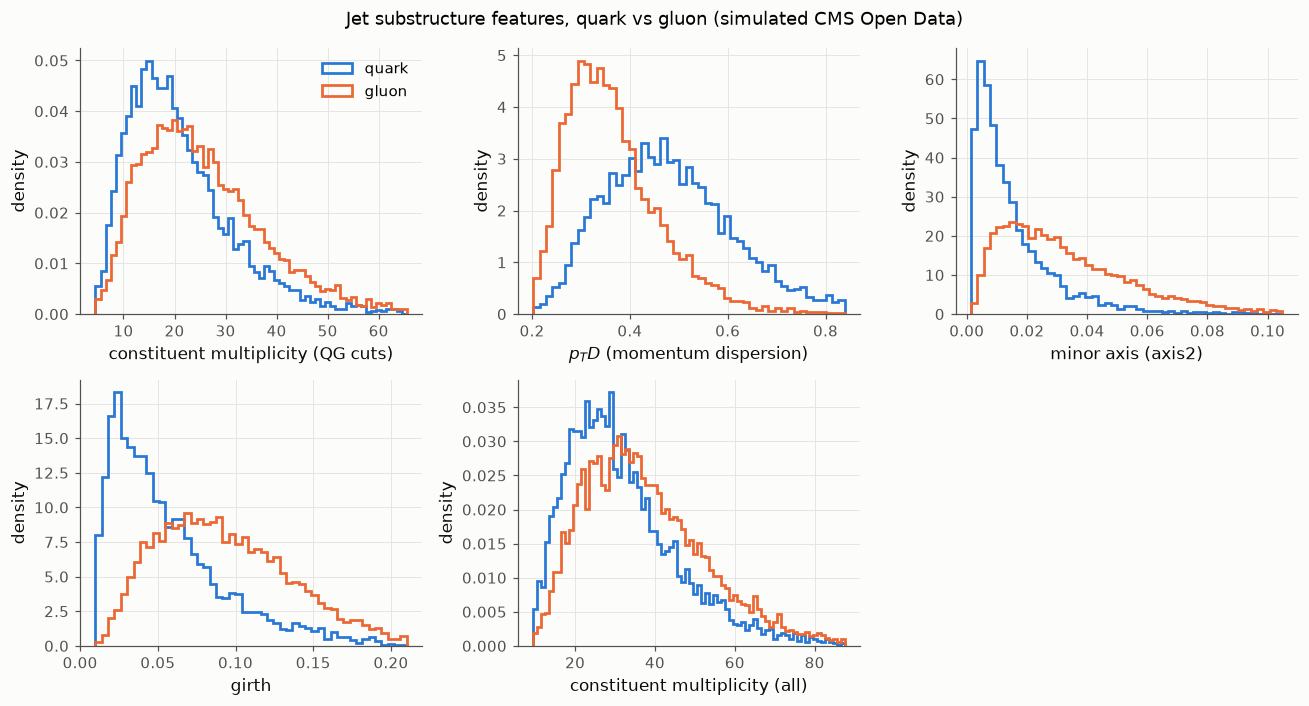

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, key in zip(axes.ravel(), CANDIDATES):
    v = np.asarray(jets[key], dtype=np.float64)
    if key in ("QG_mult", "jetMult"):
        bins = np.arange(np.percentile(v, 0.5), np.percentile(v, 99.5) + 2) - 0.5   # one bin per integer
    else:
        bins = np.linspace(np.percentile(v, 0.5), np.percentile(v, 99.5), 50)
    for label, name in ((1, "quark"), (0, "gluon")):
        ax.hist(v[y == label], bins=bins, density=True, histtype="step",
                linewidth=1.8, color=COLORS[name], label=name)
    ax.set_xlabel(LABELS[key])
    ax.set_ylabel("density")
axes[0, 0].legend()
axes[1, 2].axis("off")
fig.suptitle("Jet substructure features, quark vs gluon (simulated CMS Open Data)")
fig.tight_layout()
save(fig, "fig05_substructure_distributions")
plt.show()

## 3. Single-feature AUC

For each feature alone, the AUC answers: *if I pick a random quark jet and a random gluon jet, how often does this feature rank them correctly?*
0.5 = no information, 1.0 = perfect. A feature that is **larger for gluons** gives AUC < 0.5; we report the separation as max(AUC, 1 − AUC) and note the direction.

Computed on the **training set only**, so the choice of features does not use the test set.

In [5]:
rows = []
for key in KINEMATIC + CANDIDATES + REFERENCE:
    v = np.asarray(jets[key], dtype=np.float64)[train]
    auc = roc_auc_score(y[train], v)
    rows.append((key, max(auc, 1 - auc), "quark" if auc >= 0.5 else "gluon"))

print(f"{'feature':10s} {'separation AUC':>15s}   larger for")
for key, sep, direction in sorted(rows, key=lambda r: -r[1]):
    tag = "   (CMS reference)" if key in REFERENCE else ""
    print(f"{key:10s} {sep:15.3f}   {direction}{tag}")

feature     separation AUC   larger for
jetQGl               0.791   quark   (CMS reference)
QG_axis2             0.786   gluon
QG_ptD               0.766   quark
jetGirth             0.763   gluon
jetPt                0.662   quark
QG_mult              0.627   gluon
jetMult              0.620   gluon
jetMass              0.563   quark
jetPhi               0.503   gluon
jetEta               0.502   quark


## 4. Correlations between candidates

Two strongly correlated features carry almost the same information; keeping both wastes a slot (we have exactly 4 for 2-qubit amplitude encoding).
Spearman (rank) correlation is used because the features are not Gaussian.

In [6]:
from scipy.stats import spearmanr

M = np.stack([np.asarray(jets[k], dtype=np.float64)[train] for k in CANDIDATES], axis=1)
rho = spearmanr(M).statistic

print(" " * 10 + "".join(f"{k:>10s}" for k in CANDIDATES))
for i, k in enumerate(CANDIDATES):
    print(f"{k:10s}" + "".join(f"{rho[i, j]:10.2f}" for j in range(len(CANDIDATES))))

             QG_mult    QG_ptD  QG_axis2  jetGirth   jetMult
QG_mult         1.00     -0.53      0.08      0.14      0.93
QG_ptD         -0.53      1.00     -0.74     -0.64     -0.50
QG_axis2        0.08     -0.74      1.00      0.87      0.09
jetGirth        0.14     -0.64      0.87      1.00      0.17
jetMult         0.93     -0.50      0.09      0.17      1.00


## 5. Choose 4 features and check their scales

**Provisional choice** (edit after looking at sections 3–4): `QG_mult`, `QG_ptD`, `QG_axis2`, `jetGirth`.
`jetMult` is expected to be strongly correlated with `QG_mult`, so only one multiplicity is kept.

The order fixes the basis states: 1st → |00⟩, 2nd → |01⟩, 3rd → |10⟩, 4th → |11⟩.

In [7]:
CHOSEN = ("QG_mult", "QG_ptD", "QG_axis2", "jetGirth")

X_sub = feature_matrix(jets, features=CHOSEN)
pct = np.percentile(X_sub, [5, 50, 95], axis=0)
rms = np.sqrt(np.mean(X_sub**2, axis=0))
print(f"{'feature':10s} {'5%':>10s} {'median':>10s} {'95%':>10s} {'RMS':>10s}")
for j, key in enumerate(CHOSEN):
    print(f"{key:10s} {pct[0, j]:10.4f} {pct[1, j]:10.4f} {pct[2, j]:10.4f} {rms[j]:10.4f}")

feature            5%     median        95%        RMS
QG_mult        9.0000    22.0000    46.0000    26.6426
QG_ptD         0.2491     0.3844     0.6502     0.4286
QG_axis2       0.0037     0.0203     0.0699     0.0340
jetGirth       0.0197     0.0713     0.1631     0.0907


## 6. Raw amplitude encoding on the chosen features

Same measurement as notebook 02, now on features that carry quark/gluon information.
The dominant basis state is the one with the largest probability for each jet.

In [8]:
P_sub = amplitude_probabilities(X_sub)
dominant = P_sub.max(axis=1)
dominant_state = P_sub.argmax(axis=1)

print(f"median dominant-state probability = {np.median(dominant):.4f}")
for t in (0.90, 0.98, 0.99):
    print(f"fraction of jets with dominant probability > {t}: {np.mean(dominant > t):.3f}")
print()
for i, key in enumerate(CHOSEN):
    print(f"|{i:02b}> {key:9s} mean probability = {P_sub[:, i].mean():.2e}   dominant in {np.mean(dominant_state == i):.3f} of jets")

median dominant-state probability = 0.9997
fraction of jets with dominant probability > 0.9: 1.000
fraction of jets with dominant probability > 0.98: 0.996
fraction of jets with dominant probability > 0.99: 0.988

|00> QG_mult   mean probability = 9.99e-01   dominant in 1.000 of jets
|01> QG_ptD    mean probability = 1.05e-03   dominant in 0.000 of jets
|10> QG_axis2  mean probability = 4.22e-06   dominant in 0.000 of jets
|11> jetGirth  mean probability = 2.95e-05   dominant in 0.000 of jets


saved figures/fig06_substructure_collapse.pdf and .png


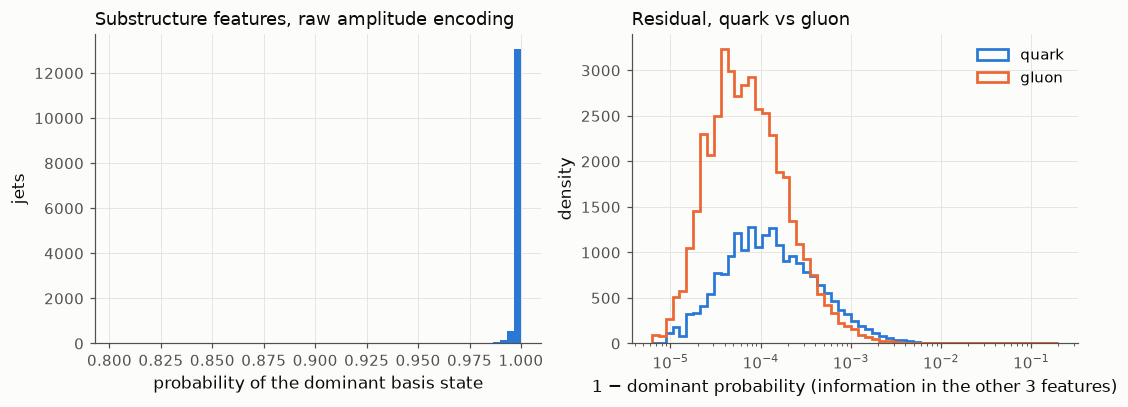

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))

ax1.hist(dominant, bins=np.linspace(dominant.min(), 1.0, 60), histtype="stepfilled",
         color=COLORS["single"], linewidth=0)
ax1.set_xlabel("probability of the dominant basis state")
ax1.set_ylabel("jets")
ax1.set_title("Substructure features, raw amplitude encoding", loc="left")

residual = 1.0 - dominant
bins = np.logspace(np.log10(max(residual.min(), 1e-6)), np.log10(residual.max()), 60)
for label, name in ((1, "quark"), (0, "gluon")):
    ax2.hist(residual[y == label], bins=bins, density=True, histtype="step",
             linewidth=1.8, color=COLORS[name], label=name)
ax2.set_xscale("log")
ax2.set_xlabel("1 − dominant probability (information in the other 3 features)")
ax2.set_ylabel("density")
ax2.set_title("Residual, quark vs gluon", loc="left")
ax2.legend()

fig.tight_layout()
save(fig, "fig06_substructure_collapse")
plt.show()

## 7. Summary for the research log

In [10]:
best = sorted(rows, key=lambda r: -r[1])
print("- Single-feature separation AUC (train): " + ", ".join(f"{k} {s:.3f}" for k, s, _ in best))
print(f"- Chosen features: {', '.join(CHOSEN)}")
print(f"- Raw amplitude encoding on chosen features: median dominant probability {np.median(dominant):.4f}; "
      f"fraction > 0.9: {np.mean(dominant > 0.9):.3f}")
print(f"- Dominant state is {CHOSEN[int(np.bincount(dominant_state).argmax())]} in "
      f"{np.bincount(dominant_state).max() / len(dominant_state):.3f} of jets")

- Single-feature separation AUC (train): jetQGl 0.791, QG_axis2 0.786, QG_ptD 0.766, jetGirth 0.763, jetPt 0.662, QG_mult 0.627, jetMult 0.620, jetMass 0.563, jetPhi 0.503, jetEta 0.502
- Chosen features: QG_mult, QG_ptD, QG_axis2, jetGirth
- Raw amplitude encoding on chosen features: median dominant probability 0.9997; fraction > 0.9: 1.000
- Dominant state is QG_mult in 1.000 of jets
